# DAY 10 牛顿法与优化进阶 coding  高斯消元

In [21]:
"""繁蝉随堂笔记"""

'繁蝉随堂笔记'

In [22]:
import numpy as np
from matplotlib.pyplot import hist
plt.rcParams['font.sans-serif']=['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 优化牛顿法：对导数做牛顿求根

def f(x):
    return (x - 3.0)**2 + 1.0

def fp(x):
    return 2.0 * (x - 3.0)

def fpp(x):
    return 2.0

x0 = 0.0
x_gd, x_nt = x0, x0
eta = 0.15
print('真值 x* = 3')
print('步 | 梯度下降   |牛顿法')
for i in range(8):
    x_gd = x_gd - eta * fp(x_gd)
    x_nt = x_nt - fp(x_nt) / fpp(x_nt)
    print(f'{i+1:2d} | {x_gd:.8f}    | {x_nt:.8f}')

真值 x* = 3
步 | 梯度下降   |牛顿法
 1 | 0.90000000    | 3.00000000
 2 | 1.53000000    | 3.00000000
 3 | 1.97100000    | 3.00000000
 4 | 2.27970000    | 3.00000000
 5 | 2.49579000    | 3.00000000
 6 | 2.64705300    | 3.00000000
 7 | 2.75293710    | 3.00000000
 8 | 2.82705597    | 3.00000000


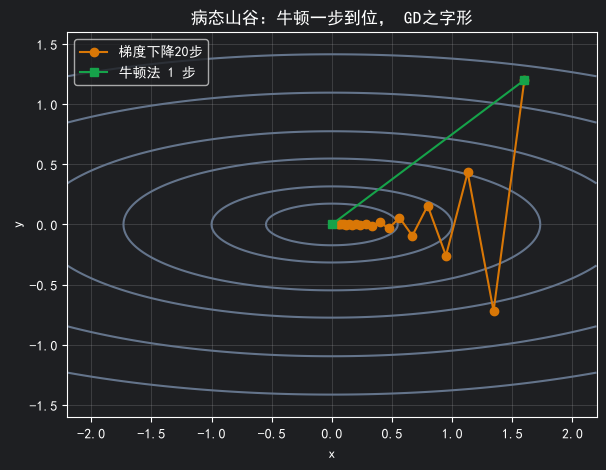

In [23]:
def path_gd(xy,eta=0.08,steps=20):
    hist = [xy.copy()]
    for _ in range(steps):
        x,y = xy
        g = np.array([2.0*x,20.0*y])
        xy = xy - eta * g
        hist.append(xy.copy())
    return np.array(hist)

def path_nt(xy):
    return np.vstack([xy,np.zeros(2)])

start = np.array([1.6,1.2])
pg,pn = path_gd(start),path_nt(start)
xs =np.linspace(-2.2,2.2,200)
ys =np.linspace(-1.6,1.6,200)
X,Y = np.meshgrid(xs,ys)

Z= X**2+10*Y**2
plt.figure(figsize=(8,5))
plt.contour(X, Y, Z, levels=[0.3, 1, 3, 6, 12, 20], colors="#64748b")
plt.plot(pg[:, 0], pg[:, 1], 'o-', color='#d97706', label='梯度下降20步')
plt.plot(pn[:, 0], pn[:, 1], 's-', color='#16a34a', label='牛顿法 1 步')
plt.legend()
plt.gca().set_aspect('equal')
plt.title('病态山谷：牛顿一步到位， GD之字形')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, alpha = 0.3)
plt.show()


In [24]:
# 参数把10改成5,25
def path_gd_c(xy,eta=0.08,steps=20):
    hist = [xy.copy()]
    for _ in range(steps):
        x,y = xy
        g = np.array([2.0*x,2.0*c*y])
        xy = xy - eta * g
        hist.append(xy.copy())
    return np.array(hist)
start = np.array([1.6,1.2])
for c in [5.0,10.0,25.0]:
    p = path_gd_c(start,c)
    print(f'c={c:4.0f} GD 第15步|y|={abs(p[-1,1]):.3e}牛顿仍一步到0')

c=   5 GD 第15步|y|=7.640e+33牛顿仍一步到0
c=  10 GD 第15步|y|=1.138e+46牛顿仍一步到0
c=  25 GD 第15步|y|=1.024e+62牛顿仍一步到0


In [25]:
def fp(x):
    return x**3 - x

def newton(x, steps=6):
    hist = [x]
    for _ in range(steps):
        h = 3 * x * x - 1
        if abs(h) < 1e-12:
            break
        x = x - fp(x) / h
        hist.append(x)
    return hist

def secant(x0, x1, steps=6):
    hist = [x0, x1]
    for _ in range(steps):
        g0, g1 = fp(x0), fp(x1)
        if abs(g1 - g0) < 1e-12:
            break
        x2 = x1 - g1 * (x1 - x0) / (g1 - g0)
        x0, x1 = x1, x2
        hist.append(x1)
    return hist

print('驻点应该接近 +-1 或者 0')
print('牛顿 x0=0.8:', [round(v, 6) for v in newton(0.8)])
print('割线 0.5,0.8:', [round(v, 6) for v in secant(0.5, 0.8)])
print('牛顿 x0=0.1:', [round(v, 6) for v in newton(0.1)], ' <- 靠近 0(极大)')

#二阶方法找的是驻点而不是最小

驻点应该接近 +-1 或者 0
牛顿 x0=0.8: [0.8, 1.113043, 1.015175, 1.000334, 1.0, 1.0, 1.0]
割线 0.5,0.8: [0.5, 0.8, 1.793103, 0.867138, 0.914708, 1.022814, 0.996857, 0.999895]
牛顿 x0=0.1: [0.1, -0.002062, 0.0, -0.0, 0.0, 0.0, 0.0]  <- 靠近 0(极大)


In [26]:
xy_nt = np.array([1.2,0.8])
g = np.array([2.0*xy_nt[0], -2.0 * xy_nt[1]])
H = np.array([[2.0,0.0],[0.0,-2.0]])
x_nt_next = xy_nt - np.linalg.solve(H,g)
print('牛顿一步',xy_nt,'-->',x_nt_next)

牛顿一步 [1.2 0.8] --> [0. 0.]


In [27]:
xy = np.array([1.2, 0.8], dtype=float)
print('GD eta=0.08')
for i in range(6):
    g = np.array([2.0 * xy[0], -2.0 * xy[1]])
    xy = xy - 0.08 * g
    print(f' 第{i+1}步 {xy}')

GD eta=0.08
 第1步 [1.008 0.928]
 第2步 [0.84672 1.07648]
 第3步 [0.7112448 1.2487168]
 第4步 [0.59744563 1.44851149]
 第5步 [0.50185433 1.68027333]
 第6步 [0.42155764 1.94911706]


In [37]:
#作业1：改参数c为50，看看GD的y是否爆炸？
for c in [5.0, 10.0, 25.0, 50.0]:
    p = path_gd_c(start, c)
    print(f"c={c:5.1f}  第{c}步 |y|={abs(p[-1,1]):.3e}, y={p[-1,1]:.3e}")

c=  5.0  第5.0步 |y|=7.640e+33, y=7.640e+33
c= 10.0  第10.0步 |y|=1.138e+46, y=1.138e+46
c= 25.0  第25.0步 |y|=1.024e+62, y=1.024e+62
c= 50.0  第50.0步 |y|=1.140e+74, y=1.140e+74


In [29]:
#作业2：coding出牛顿法、泰勒展开、麦克劳林、拟牛顿法、XGBoost、LightGBM的动态运行图，每个理论方法需要附上不少于200字的观察与理解，格式采用html+css。
